# Statistical jump model vs volatility targeting (pre-registered, run once)

**Claim under test.** A statistical jump model (SJM) fixes the HMM's turnover and instability through an explicit switching penalty, and therefore is a better regime-based risk signal than simple volatility targeting. (Shu, Yu & Mulvey, arXiv 2402.05272 report SJM beating buy-and-hold and an HMM on the S&P 500, DAX and Nikkei over 1990-2023; they do **not** compare against vol-targeting, so that comparison is new.)

## Design (fixed before running; follows the paper where the data allow)

| Item | Setting |
|---|---|
| Model | 2-state SJM: `sum 0.5*||x_t - mu_s||^2 + lambda * #jumps`, coordinate descent + dynamic programming, best of 10 restarts |
| Features (return-only, as in the paper) | EWM downside deviation (half-life 10), EWM Sortino (half-lives 20 and 60), computed on excess returns, standardised on the training window |
| Online signal | centroids fixed; regime on day *t* = last state of the optimal path ending at *t* (computed by an exactly-equivalent forward pass; unit-tested) |
| Strategy | **0/1**: 100% index in the bull state (higher training excess return), cash otherwise |
| lambda | grid {5, 10, 25, 50, 100, 200}; chosen at each refit by **validation Sharpe** over the preceding 2 years (centroids fit before the validation window; no data from the fold itself) |
| Walk-forward | 4y warm-up, refit every 126 days, expanding training window |
| Execution | signal at close *t* trades at close *t+1*, first earns day *t+2* (paper's 1-day delay); **10 bps** one-way; cash earns 6% (Nifty) / 2% (S&P) |
| Benchmarks (identical delay and costs) | **EWMA vol-targeting** (lambda 0.94, target 12%, cap 100%); **VIX vol-targeting** (same target, VIX rescaled by a causal rolling realised/implied ratio); the 3-state **HMM soft overlay** from earlier work; buy & hold |

Primary market: **Nifty 50 + India VIX**, OOS ~2013 -> 2026. Replication (cannot rescue a primary failure): **S&P 500 + VIX**, OOS ~2004 -> 2026.

## Kill rule

The jump model is **rejected** as a better risk signal than vol-targeting unless **both**:

* **(C1, the persistence claim)** SJM has a longer mean regime run length **and** lower annual turnover than the HMM soft overlay.
* **(C2, performance)** Net-of-cost Sharpe(SJM) - Sharpe(EWMA vol-target) > 0 **and** Sharpe(SJM) - Sharpe(VIX vol-target) > 0, each with moving-block-bootstrap (20-day blocks, 2,000 draws) **P(diff <= 0) < 0.10**.

Pass both on Nifty but fail on S&P -> not robust, not adopted. Drawdown, Calmar, sub-period results and chosen lambdas are **descriptive**. No variants will be tried after this run.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, jump_model as jm

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
TARGET, COST = 0.12, 10.0

def run_market(df, rf_annual, label):
    feats = rf.build_features(df); idx = feats.index
    ret_full = df["close"].pct_change()
    ret = ret_full.reindex(idx)

    # --- 3-state HMM soft overlay (same warm-up as the SJM so OOS windows match)
    res = rf.walk_forward(feats, ret, rf.WFConfig(n_states=3, cov_type="diag", warmup_days=1008, refit_days=126, n_init=10, seed=42))
    P = res.probs
    e_hmm = rf.soft_exposure(P, res.state_vol, TARGET)

    # --- SJM
    X = jm.sjm_features(ret_full, rf_annual).reindex(idx)
    J = jm.jm_walk_forward(X, ret, jm.JMConfig(rf_annual=rf_annual, cost_bps=COST))
    e_jm = J["bull"]

    # --- vol-targeting benchmarks (causal, over full history then cut to OOS)
    rr = ret_full.dropna()
    e_ewma = jm.ewma_vol_target_exposure(rr, TARGET).reindex(P.index)
    e_vix = jm.vix_vol_target_exposure(rr, df["vix"], TARGET).reindex(P.index)
    expo = {"SJM (0/1)": e_jm, "HMM soft": e_hmm, "EWMA vol-target": e_ewma, "VIX vol-target": e_vix,
            "Buy & hold": pd.Series(1.0, index=P.index)}
    # extra shift(1) => signal at close t earns day t+2 (rf.backtest already lags one day)
    rets = {k: rf.backtest(ret.reindex(P.index), v.shift(1), rf_annual, COST).dropna() for k, v in expo.items()}
    common = rets["SJM (0/1)"].index
    for k in rets: common = common.intersection(rets[k].index)
    rets = {k: v.loc[common] for k, v in rets.items()}
    tab = pd.DataFrame({k: rf.perf(rets[k], expo[k], rf_annual) for k in rets})
    print(f"[{label}] OOS {common.min().date()} -> {common.max().date()} ({len(common)} days); SJM lambdas by fold: {J['lams']}")
    return dict(tab=tab, rets=rets, expo=expo, P=P, J=J, rf_annual=rf_annual, common=common, ret=ret)

def verdict(R, label):
    rets, expo, P, J, rfa = R["rets"], R["expo"], R["P"], R["J"], R["rf_annual"]
    runs_jm = rf.run_lengths(expo["SJM (0/1)"].astype(int))["duration"].mean()
    runs_hmm = rf.run_lengths(P.idxmax(axis=1))["duration"].mean()
    t_jm = expo["SJM (0/1)"].diff().abs().mean() * rf.TRADING_DAYS
    t_hmm = expo["HMM soft"].diff().abs().mean() * rf.TRADING_DAYS
    c1 = (runs_jm > runs_hmm) and (t_jm < t_hmm)
    print(f"[{label}] C1: mean run length SJM={runs_jm:.1f}d vs HMM={runs_hmm:.1f}d; turnover SJM={t_jm:.2f} vs HMM={t_hmm:.2f}/yr -> {'PASS' if c1 else 'FAIL'}")
    ok = []
    for b in ["EWMA vol-target", "VIX vol-target"]:
        pt, lo, hi, p = rf.block_bootstrap_sharpe_diff(rets["SJM (0/1)"], rets[b], rfa)
        good = pt > 0 and p < 0.10
        ok.append(good)
        print(f"[{label}] C2 vs {b}: dSharpe={pt:+.3f} (95% CI {lo:+.3f}..{hi:+.3f}), P(diff<=0)={p:.3f} -> {'PASS' if good else 'FAIL'}")
    c2 = all(ok)
    return c1, c2

## 1. Primary: Nifty 50 + India VIX

In [2]:
import regime_allocation as ra
px = ra.download_assets()
nifty = pd.DataFrame({"close": px["nifty"], "vix": px["vix"]})
RN = run_market(nifty, 0.06, "Nifty")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RN["tab"]

[Nifty] OOS 2013-03-21 -> 2026-10-16 (3292 days); SJM lambdas by fold: [200, 5, 5, 10, 25, 5, 10, 5, 10, 10, 5, 5, 5, 5, 100, 200, 200, 200, 10, 100, 100, 100, 200, 25, 100, 50, 100]


,SJM (0/1),HMM soft,EWMA vol-target,VIX vol-target,Buy & hold
CAGR,0.100,0.085,0.085,0.083,0.113
AnnVol,0.092,0.121,0.118,0.118,0.163
Sharpe,0.453,0.250,0.257,0.242,0.383
Sortino,0.637,0.343,0.353,0.332,0.526
MaxDD,-0.158,-0.222,-0.194,-0.202,-0.384
Calmar,0.637,0.380,0.438,0.411,0.295
AvgExposure,0.521,0.849,0.842,0.855,1.000
AnnTurnover,2.527,2.334,3.806,5.013,0.000


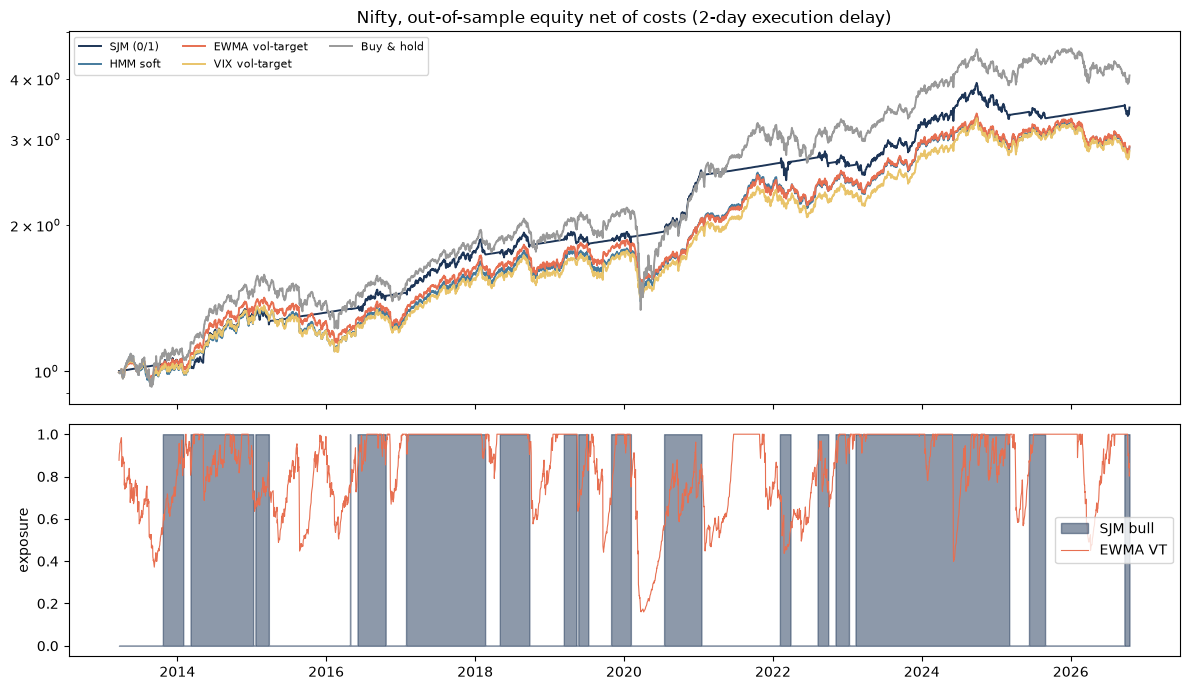

Sub-period Sharpe:


,2013-2016,2017-2021,2022-2026
SJM (0/1),0.543,0.874,0.043
HMM soft,0.093,0.706,-0.116
EWMA vol-target,0.140,0.665,-0.072
VIX vol-target,0.057,0.642,-0.030
Buy & hold,0.349,0.621,0.094


In [3]:
rets, expo = RN["rets"], RN["expo"]
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
pal = {"SJM (0/1)": "#1d3557", "HMM soft": "#457b9d", "EWMA vol-target": "#e76f51", "VIX vol-target": "#e9c46a", "Buy & hold": "#999999"}
for k, r in rets.items(): ax[0].plot((1 + r).cumprod(), label=k, color=pal[k], lw=1.4)
ax[0].set_yscale("log"); ax[0].legend(ncol=3, fontsize=8); ax[0].set_title("Nifty, out-of-sample equity net of costs (2-day execution delay)")
ax[1].fill_between(expo["SJM (0/1)"].reindex(rets["Buy & hold"].index).index, expo["SJM (0/1)"].reindex(rets["Buy & hold"].index), step="post", color="#1d3557", alpha=0.5, label="SJM bull")
ax[1].plot(expo["EWMA vol-target"].reindex(rets["Buy & hold"].index), color="#e76f51", lw=0.8, label="EWMA VT"); ax[1].legend(); ax[1].set_ylabel("exposure")
plt.tight_layout(); plt.show()
sub = {}
for lo, hi in [("2013", "2016"), ("2017", "2021"), ("2022", "2026")]:
    sub[f"{lo}-{hi}"] = pd.Series({k: rf.perf(r.loc[lo:hi], None, 0.06)["Sharpe"] for k, r in rets.items()})
print("Sub-period Sharpe:"); display(pd.DataFrame(sub))

In [4]:
c1_n, c2_n = verdict(RN, "Nifty")
print("\nNIFTY VERDICT:", "C1 and C2 pass -> check S&P replication" if (c1_n and c2_n) else "KILL RULE TRIGGERED -> jump model rejected vs vol-targeting")

[Nifty] C1: mean run length SJM=96.9d vs HMM=30.8d; turnover SJM=2.52 vs HMM=2.33/yr -> FAIL


[Nifty] C2 vs EWMA vol-target: dSharpe=+0.196 (95% CI -0.250..+0.663), P(diff<=0)=0.215 -> FAIL


[Nifty] C2 vs VIX vol-target: dSharpe=+0.211 (95% CI -0.242..+0.702), P(diff<=0)=0.196 -> FAIL

NIFTY VERDICT: KILL RULE TRIGGERED -> jump model rejected vs vol-targeting


## 2. Replication: S&P 500 + VIX (cannot rescue a Nifty failure)

In [5]:
sp = pd.read_csv("sp500_vix.csv", index_col=0, parse_dates=True)
RS = run_market(sp, 0.02, "S&P 500")
display(RS["tab"])
c1_s, c2_s = verdict(RS, "S&P 500")

[S&P 500] OOS 2004-02-11 -> 2026-10-19 (5708 days); SJM lambdas by fold: [50, 100, 25, 10, 100, 100, 100, 50, 100, 50, 100, 100, 5, 5, 25, 5, 5, 200, 200, 50, 50, 25, 25, 25, 50, 200, 200, 200, 200, 50, 50, 200, 50, 25, 25, 25, 25, 25, 25, 50, 50, 50, 50, 200, 25, 5]


,SJM (0/1),HMM soft,EWMA vol-target,VIX vol-target,Buy & hold
CAGR,0.067,0.065,0.072,0.062,0.088
AnnVol,0.115,0.115,0.114,0.114,0.187
Sharpe,0.445,0.429,0.496,0.413,0.437
Sortino,0.604,0.586,0.678,0.562,0.611
MaxDD,-0.218,-0.327,-0.274,-0.322,-0.568
Calmar,0.306,0.197,0.265,0.193,0.154
AvgExposure,0.756,0.799,0.822,0.820,1.000
AnnTurnover,1.501,3.048,3.175,6.540,0.000


[S&P 500] C1: mean run length SJM=163.2d vs HMM=22.7d; turnover SJM=1.50 vs HMM=3.05/yr -> PASS


[S&P 500] C2 vs EWMA vol-target: dSharpe=-0.051 (95% CI -0.268..+0.176), P(diff<=0)=0.658 -> FAIL


[S&P 500] C2 vs VIX vol-target: dSharpe=+0.032 (95% CI -0.224..+0.289), P(diff<=0)=0.389 -> FAIL


In [6]:
print("=" * 72)
if not (c1_n and c2_n):
    final = "REJECTED: jump model fails the pre-registered rule on the primary (Nifty) market. FINAL."
elif c1_s and c2_s:
    final = "SURVIVES both markets."
else:
    final = "NOT ROBUST: passes on Nifty but fails on S&P 500; not adopted."
print("FINAL VERDICT:", final)

FINAL VERDICT: REJECTED: jump model fails the pre-registered rule on the primary (Nifty) market. FINAL.


## Conclusions (final)

**Verdict under the pre-registered rule: the jump model is rejected** as a demonstrably better risk signal than vol-targeting. It fails on the primary (Nifty) market on both conditions, and fails C2 on the S&P replication.

**Nifty (OOS 2013-03 -> 2026-10, 3,292 days, 10 bps, 2-day delay):**

| | SJM 0/1 | HMM soft | EWMA vol-target | VIX vol-target | Buy & hold |
|---|---|---|---|---|---|
| Sharpe | 0.45 | 0.25 | 0.26 | 0.24 | 0.38 |
| Max drawdown | -15.8% | -22.2% | -19.4% | -20.2% | -38.4% |
| Avg exposure | 0.52 | 0.85 | 0.84 | 0.86 | 1.00 |

* **C1 fails, narrowly and for a technical reason.** The SJM's regimes are far more persistent (mean run 97 days vs 31 for the HMM), but its annual turnover is 2.53 vs the HMM's 2.33, so the "lower turnover" half of the condition fails as written. This is partly an artefact of how the two are traded: the SJM makes ~2.5 full-size 0/1 switches a year, whereas the HMM overlay makes many small exposure adjustments. Per the pre-registration this is a FAIL; it is reported as a nuance, not a revision.
* **C2 fails on significance, not on point estimates.** The SJM's Sharpe is higher than both vol-targets (+0.20 and +0.21) with a better drawdown, but the block-bootstrap intervals are wide (-0.25 to +0.66 and -0.24 to +0.70) and P(diff <= 0) = 0.22 and 0.20, nowhere near the 0.10 bar. With ~13 years and a handful of stress episodes the data cannot separate them.
* **Worth knowing, not a rescue:** the SJM sits in cash about half the time (avg exposure 0.52), so on Nifty it is partly harvesting the flat 6% cash rate against ~11% buy-and-hold; the sub-period Sharpes are 0.54 / 0.87 / 0.04 across 2013-16 / 2017-21 / 2022-26, i.e. all of its edge over vol-targeting came before 2022. The validation-chosen lambda also swings between 5 and 200 from one refit to the next, which is exactly the kind of parameter instability the method is meant to avoid.

**S&P 500 replication (2004-02 -> 2026-10):** persistence claim holds (C1 passes: mean run 163 days vs 23, turnover 1.50 vs 3.05 per year), and drawdown is much better (-21.8% vs -27.4% / -32.2% for the vol-targets and -56.8% for buy & hold). But the Sharpe is no better than EWMA vol-targeting (0.445 vs 0.496, dSharpe -0.05, P(diff <= 0) = 0.66) and only marginally above VIX vol-targeting (+0.03, P = 0.39).

**What this does and does not show.** Jump models do deliver what they claim about persistence and drawdown reduction (clearly on the S&P, in point estimates on Nifty). They do **not** show a statistically distinguishable Sharpe advantage over a trailing-vol rule on either market in this sample. The honest reading is "plausibly useful for cutting drawdowns, unproven as a better risk-adjusted signal", and the pre-registered answer is final: no variants (other lambda rules, features, K, vol-scaled exposure) will be tried here. Not tested: the paper's 3,000-day window and 8-year validation (not feasible on ~17 years of Nifty data), total-return index series, and tradable-instrument costs.
